<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Week 2 — Root-Finding: Solving Kepler's Equation</div>
</div>

<div style="background-color:#38614A;color:#ffffff;padding:10px 16px;border-radius:4px;font-family:Arial, Helvetica, sans-serif;font-weight:700;margin-top:10px;">
Worked solutions: try each exercise yourself first, then compare.
</div>

#### Lecture 3 introduced bisection and Newton–Raphson on Kepler's equation. Here you implement both, find where each one wins and how Newton fails, and use your root-finder to compute an orbit.
***

## Where this fits

In the Week 1 extension you computed an orbit by stepping through time with Euler and RK4. Lecture 3 showed a second route. **Kepler's equation** gives the position on an elliptical orbit at any time directly:

$$M = E - e\sin E,$$

where $M = 2\pi t/T$ is the *mean anomaly* (known from the clock), $e$ is the eccentricity and $E$ is the *eccentric anomaly*, which gives the position: $x = a(\cos E - e)$, $y = b\sin E$.

There is no closed-form solution for $E$, so we solve $f(E) = E - e\sin E - M = 0$ numerically. Today you will:

1. implement bisection and Newton–Raphson;
2. compare how fast they converge, and reproduce the table from the lecture;
3. find out how Newton can go wrong;
4. check your answers against SciPy;
5. use your root-finder to compute an orbit, and compare it with RK4.

The functions you write take another function as an input (`bisection(f, a, b)`). If `lambda` or passing functions around is new to you, work through `week2_python_functions.ipynb` first (about 15 minutes).

**Nothing here is assessed.** Write your predictions in your logbook before you run each comparison.

## <span style="color:#B5121B">0. The problem (provided)</span>

$f(E) = E - e\sin E - M$ and its derivative $f'(E) = 1 - e\cos E$. Since $0 \le e < 1$, $f'(E) > 0$: $f$ is increasing, so there is exactly one root. Because $|E - M| = e|\sin E| \le e$, the root lies in $[M - e, M + e]$, a ready-made bracket.

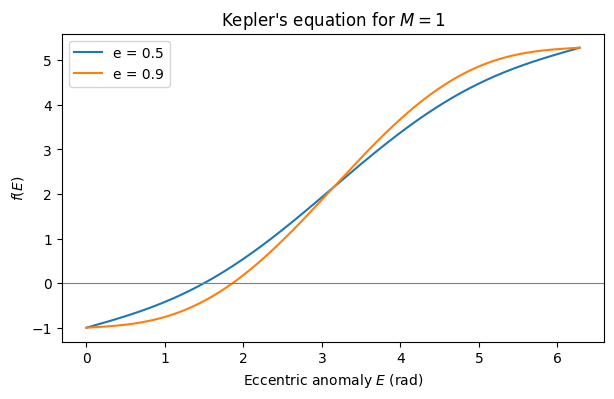

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def kepler_f(E, e, M):
    """Kepler's equation written as f(E) = 0."""
    return E - e * np.sin(E) - M

def kepler_fprime(E, e):
    """Derivative of kepler_f with respect to E."""
    return 1 - e * np.cos(E)

E = np.linspace(0, 2 * np.pi, 400)
M = 1.0
fig, ax = plt.subplots(figsize=(7, 4))
for e in [0.5, 0.9]:
    ax.plot(E, kepler_f(E, e, M), label=f"e = {e}")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Eccentric anomaly $E$ (rad)")
ax.set_ylabel("$f(E)$")
ax.set_title("Kepler's equation for $M = 1$")
ax.legend()
plt.show()

## <span style="color:#B5121B">1. Implement bisection</span>

From the lecture: if $f(a)\,f(b) < 0$, a root lies in $[a, b]$.

1. Take the midpoint $m = (a + b)/2$.
2. Keep the half in which the sign changes.
3. Repeat until the bracket is narrower than `tol`.

Write `bisection(f, a, b, tol)` returning the root and a list of the midpoints (the *history*), so we can count iterations later. Raise a `ValueError` if `f(a)` and `f(b)` have the same sign.

In [2]:
def bisection(f, a, b, tol=1e-12, max_iter=200):
    """Find a root of f in [a, b] by bisection.

    Returns (root, history), where history lists the midpoints tried.
    """
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError("f(a) and f(b) must have opposite signs")
    history = []
    for _ in range(max_iter):
        m = 0.5 * (a + b)
        history.append(m)
        fm = f(m)
        if fa * fm <= 0:
            b, fb = m, fm
        else:
            a, fa = m, fm
        if (b - a) < tol:
            break
    return 0.5 * (a + b), history

<details><summary><b>Stuck? Open a hint</b> (try for 10 minutes first)</summary>

* Check the signs of `f(a)` and `f(b)` first; `raise ValueError(...)` if they match.
* Inside a `for` loop over `range(max_iter)`: compute the midpoint, append it to the history, and decide which end of the bracket it replaces. The product of two function values tells you whether they have opposite signs.
* `break` out of the loop once `b - a < tol`.

</details>

In [3]:
# Test on e = 0.5, M = 1, bracket [M - e, M + e]
e, M = 0.5, 1.0
try:
    root, hist = bisection(lambda E: kepler_f(E, e, M), M - e, M + e)
    print(f"root E = {root:.12f} after {len(hist)} steps")
    print(f"f(root) = {kepler_f(root, e, M):.1e}")
    print(f"expected steps ≈ log2((b - a)/tol) = {np.log2(2 * e / 1e-12):.1f}")
except NotImplementedError:
    print("Not implemented yet: complete the function above, then re-run this cell.")

root E = 1.498701133517 after 40 steps
f(root) = -3.9e-13
expected steps ≈ log2((b - a)/tol) = 39.9


## <span style="color:#B5121B">2. Implement Newton–Raphson</span>

From the lecture: replace $f$ by its tangent at $x_n$ and move to where the tangent crosses zero,

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}.$$

Write `newton(f, fprime, x0, tol, max_iter)` returning the root and the history of iterates. Stop when the step $|x_{n+1} - x_n|$ is smaller than `tol`. If `max_iter` is reached first, print a warning: a root-finder that silently returns a wrong answer is worse than one that complains.

In [4]:
def newton(f, fprime, x0, tol=1e-12, max_iter=50):
    """Find a root of f by Newton-Raphson, starting from x0.

    Returns (root, history), where history lists every iterate (x0 included).
    """
    x = x0
    history = [x0]
    for _ in range(max_iter):
        step = -f(x) / fprime(x)
        x = x + step
        history.append(x)
        if abs(step) < tol:
            return x, history
    print(f"Warning: no convergence after {max_iter} iterations (last step {step:.1e})")
    return x, history

<details><summary><b>Stuck? Open a hint</b> (try for 10 minutes first)</summary>

* Keep the current estimate and a list starting with `x0`.
* Each pass of the loop: compute the step from the formula above, update the estimate, append it, and `return` as soon as the step is smaller than `tol`.
* If the loop ends without returning, print a warning, then return what you have.

</details>

In [5]:
e, M = 0.5, 1.0
try:
    root, hist = newton(lambda E: kepler_f(E, e, M), lambda E: kepler_fprime(E, e), x0=M)
    print(f"root E = {root:.12f} after {len(hist) - 1} steps")
except NotImplementedError:
    print("Not implemented yet: complete the function above, then re-run this cell.")

root E = 1.498701133518 after 5 steps


## <span style="color:#B5121B">3. Round 1: how fast?</span>

**Before running, predict in your logbook:** how many iterations will each method need to reach $10^{-12}$?

For $M = 1$ and $e = 0.5$ and $0.9$:

1. find an accurate reference root (`scipy.optimize.brentq` with `xtol=1e-15` is fine);
2. run both methods, starting Newton from $E_0 = M$ and bisection on $[M - e, M + e]$;
3. plot the error $|E_n - E_\text{exact}|$ against iteration $n$ on a log scale, for both methods and both eccentricities;
4. print Newton's errors and compare them with the table on Lecture 3, slide 7.

e = 0.5: Newton errors 8e-02 2e-03 6e-07 9e-14 0e+00
        bisection steps: 40, Newton steps: 5
e = 0.9: Newton errors 6e-01 7e-02 2e-03 1e-06 4e-13 0e+00
        bisection steps: 41, Newton steps: 6


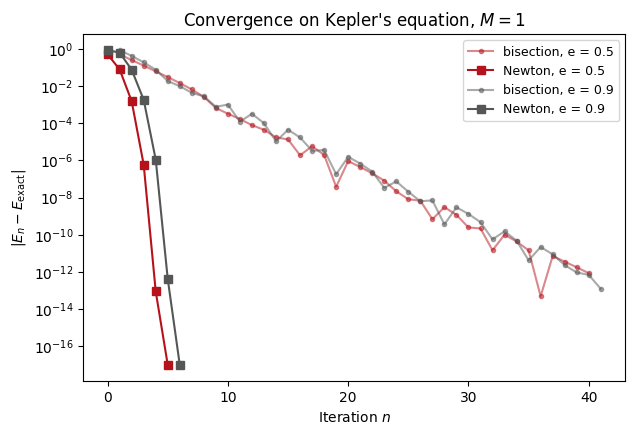

In [6]:
from scipy.optimize import brentq

M = 1.0
fig, ax = plt.subplots(figsize=(7, 4.5))
for e, colour in [(0.5, "#B5121B"), (0.9, "#555656")]:
    f = lambda E: kepler_f(E, e, M)
    fp = lambda E: kepler_fprime(E, e)
    E_exact = brentq(f, M - e, M + e, xtol=1e-15)

    _, hist_b = bisection(f, M - e, M + e)
    _, hist_n = newton(f, fp, x0=M)
    err_b = np.abs(np.array(hist_b) - E_exact)
    err_n = np.abs(np.array(hist_n) - E_exact)

    ax.semilogy(range(1, len(err_b) + 1), err_b, "o-", ms=3, color=colour, alpha=0.5,
                label=f"bisection, e = {e}")
    ax.semilogy(range(len(err_n)), np.maximum(err_n, 1e-17), "s-", color=colour,
                label=f"Newton, e = {e}")
    print(f"e = {e}: Newton errors", " ".join(f"{x:.0e}" for x in err_n[1:]))
    print(f"        bisection steps: {len(hist_b)}, Newton steps: {len(hist_n) - 1}")

ax.set_xlabel("Iteration $n$")
ax.set_ylabel("$|E_n - E_\\mathrm{exact}|$")
ax.set_title("Convergence on Kepler's equation, $M = 1$")
ax.legend(fontsize=9)
plt.show()

<span style="color:#38614A">**Answer.**</span> Newton reproduces the lecture's table: for $e = 0.5$ the errors go 8e-2, 2e-3, 6e-7, 9e-14, so the number of correct digits roughly doubles each step (quadratic convergence); $e = 0.9$ takes one or two more steps. Bisection needs about 40 steps either way: it gains one binary digit (≈0.3 decimal digits) per step regardless of $e$, and its step count follows $\log_2((b-a)/\text{tol})$. The straight line of bisection on the log plot is linear convergence; Newton's curve bends downward.

In your logbook: how many decimal digits does each method gain per step? Does the eccentricity change bisection's step count? Why not?

## <span style="color:#B5121B">4. Round 2: break it</span>

The lecture listed ways Newton can fail.

**High eccentricity.** Take $e = 0.99$ and $M = 0.2$. Start Newton from $E_0 = M$, then from $E_0 = 0$, then from $E_0 = \pi$. For each, print the number of iterations and the largest $|E|$ visited (`max(abs(np.array(history)))`). What happens to Newton's first step, and why? (Look at $f'(E)$ near $E = 0$.) Then try `max_iter=10` from $E_0 = M$.

In [7]:
# (a) high eccentricity
e, M = 0.99, 0.2
f = lambda E: kepler_f(E, e, M)
fp = lambda E: kepler_fprime(E, e)
for E0 in [M, 0.0, np.pi]:
    root, hist = newton(f, fp, E0)
    print(f"E0 = {E0:.3f}: {len(hist) - 1:2d} steps, root {root:.6f}, "
          f"largest |E| visited {max(abs(np.array(hist))):.1f}")
print("With max_iter = 10 from E0 = M:")
root, hist = newton(f, fp, M, max_iter=10)
print(f"  returned {root:.4f}, f = {f(root):.2e}")

E0 = 0.200: 19 steps, root 1.066997, largest |E| visited 1126.7
E0 = 0.000: 25 steps, root 1.066997, largest |E| visited 195700.3
E0 = 3.142:  7 steps, root 1.066997, largest |E| visited 3.1
With max_iter = 10 from E0 = M:
  returned 1126.7014, f = 1.13e+03


<span style="color:#38614A">**Answer.**</span> Near $E = 0$, $f'(E) = 1 - 0.99\cos E \approx 0.01$, so the first Newton step is about 100 times too large: from $E_0 = M$ it jumps to $|E| \approx 1100$ and takes 19 steps to come back; from $E_0 = 0$ it visits $|E| \approx 2\times10^5$. Because $f$ is monotonic for Kepler's equation it does eventually converge, but with `max_iter=10` it stops far from the root (and our function warns). From $E_0 = \pi$, where $f'(\pi) = 1 + e \ge 1$, it converges in 7 steps: $E_0 = \pi$ is a safe start for any $e$, and $E_0 = M$ is fine only for small $e$.

### <span style="color:#FD9029">Optional: Newton that never converges</span>

Newton on $f(x) = x^3 - 2x + 2$, starting from $x_0 = 0$. Print the first few iterates. Then find the root with bisection on $[-3, 0]$.

In [8]:
g = lambda x: x**3 - 2 * x + 2
gp = lambda x: 3 * x**2 - 2
root, hist = newton(g, gp, 0.0, max_iter=10)
print("Newton iterates:", np.round(hist, 3))
root_b, _ = bisection(g, -3, 0)
print(f"Bisection root: {root_b:.6f}, g = {g(root_b):.1e}")

Newton iterates: [0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 0.]
Bisection root: -1.769292, g = -2.2e-12


<span style="color:#38614A">**Answer.**</span> Newton cycles 0 → 1 → 0 → 1 … forever and never converges. Bisection, given a bracket, finds the root at $x \approx -1.769$. This is the lecture's trade-off: Newton is fast near the root, only bisection is guaranteed, and Brent's method combines the two.

## <span style="color:#B5121B">5. Check against SciPy</span>

In practice you'd use a library routine. The lecture recommended `scipy.optimize.brentq` (bracketed, guaranteed and fast). `scipy.optimize.newton` is also available. Solve $e = 0.9$, $M = 1$ with both and check that they agree with your functions to $10^{-12}$. Use `full_output=True` to see how many iterations they needed.

In [9]:
from scipy.optimize import newton as sp_newton

e, M = 0.9, 1.0
f = lambda E: kepler_f(E, e, M)
fp = lambda E: kepler_fprime(E, e)

root_brent, info = brentq(f, M - e, M + e, xtol=1e-14, full_output=True)
root_sp = sp_newton(f, x0=M, fprime=fp, tol=1e-14)
root_bis, _ = bisection(f, M - e, M + e)
root_new, _ = newton(f, fp, M)

print(f"brentq        : {root_brent:.14f}  ({info.iterations} iterations)")
print(f"scipy newton  : {root_sp:.14f}")
print(f"my bisection  : {root_bis:.14f}")
print(f"my newton     : {root_new:.14f}")
print("all agree to 1e-12:", np.allclose([root_sp, root_bis, root_new], root_brent, atol=1e-12, rtol=0))

brentq        : 1.86208668687453  (6 iterations)
scipy newton  : 1.86208668687453
my bisection  : 1.86208668687482
my newton     : 1.86208668687453
all agree to 1e-12: True


## <span style="color:#FD9029">6. Optional: from Kepler's equation to an orbit</span>

*Optional in the lab: it links back to the Week 1 orbit, and it's a good one to finish in your own time.*

The Week 1 extension suggested an eccentric orbit: $GM = 1$, starting at $(x, y) = (1, 0)$ with velocity $(0, 0.7)$. The cell below works out its orbital elements (semi-major axis $a$, eccentricity $e$, period $T$) and integrates one period with RK4, as in Week 1.

The body starts at the far point of the orbit (apoapsis), which corresponds to $E = \pi$. So here $M = \pi + 2\pi t/T$, and, with the orbit's long axis along $x$,

$$x = -a(\cos E - e), \qquad y = -b\sin E, \qquad b = a\sqrt{1 - e^2}.$$

In [10]:
GM = 1.0
x0, y0, vx0, vy0 = 1.0, 0.0, 0.0, 0.7

# Orbital elements from the initial conditions (energy and angular momentum)
r0 = np.hypot(x0, y0)
a = 1 / (2 / r0 - (vx0**2 + vy0**2) / GM)        # semi-major axis
h_ang = x0 * vy0 - y0 * vx0                       # angular momentum per unit mass
ecc = np.sqrt(1 - h_ang**2 / (GM * a))            # eccentricity
b = a * np.sqrt(1 - ecc**2)                       # semi-minor axis
T = 2 * np.pi * np.sqrt(a**3 / GM)                # period
print(f"a = {a:.4f}, e = {ecc:.4f}, b = {b:.4f}, T = {T:.4f}")

def orbit_deriv(s):
    x, y, vx, vy = s
    r3 = (x**2 + y**2) ** 1.5
    return np.array([vx, vy, -GM * x / r3, -GM * y / r3])

def rk4_orbit(state0, h, n_steps):
    s = np.array(state0, dtype=float)
    out = [s.copy()]
    for _ in range(n_steps):
        k1 = orbit_deriv(s)
        k2 = orbit_deriv(s + h / 2 * k1)
        k3 = orbit_deriv(s + h / 2 * k2)
        k4 = orbit_deriv(s + h * k3)
        s = s + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        out.append(s.copy())
    return np.array(out)

h_step = 0.01
n_steps = int(round(T / h_step))
t_rk4 = np.arange(n_steps + 1) * h_step
orbit_rk4 = rk4_orbit((x0, y0, vx0, vy0), h_step, n_steps)

a = 0.6623, e = 0.5100, b = 0.5697, T = 3.3862


For each time in `t_rk4`, solve Kepler's equation for $E$ with your `newton` function, convert to $(x, y)$, and:

1. plot both orbits on the same axes (`ax.set_aspect("equal")`);
2. print the largest distance between the two positions at the same time.

Which method would you trust to give the position after 1000 orbits, and why?

<details><summary><b>Stuck? Open a hint</b> (try for 10 minutes first)</summary>

Loop over `t_rk4`. For each time, compute $M$, then fix $e$ and $M$ with a `lambda` so that `newton` sees a function of $E$ only (`week2_python_functions.ipynb`, Section 4). `M` itself is a good starting value. Store $x$ and $y$ in arrays, then compare with `orbit_rk4[:, 0]` and `orbit_rk4[:, 1]`.

</details>

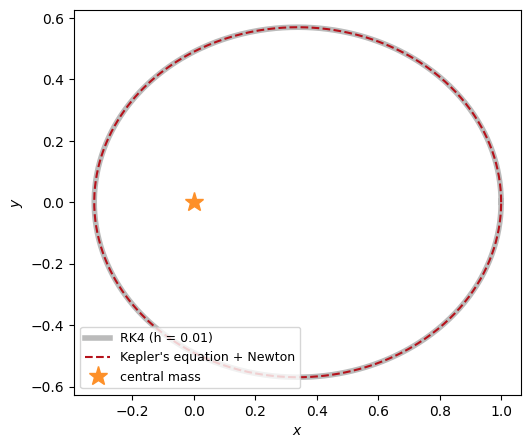

largest difference over one orbit: 7.6e-07


In [11]:
x_kep = np.empty_like(t_rk4)
y_kep = np.empty_like(t_rk4)
for i, t in enumerate(t_rk4):
    M = np.pi + 2 * np.pi * t / T
    E = newton(lambda E: kepler_f(E, ecc, M), lambda E: kepler_fprime(E, ecc), x0=M)[0]
    x_kep[i] = -a * (np.cos(E) - ecc)
    y_kep[i] = -b * np.sin(E)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(orbit_rk4[:, 0], orbit_rk4[:, 1], color="#555656", lw=4, alpha=0.4, label="RK4 (h = 0.01)")
ax.plot(x_kep, y_kep, "--", color="#B5121B", label="Kepler's equation + Newton")
ax.plot(0, 0, "*", color="#FD9029", ms=14, label="central mass")
ax.set_aspect("equal")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.legend(loc="lower left", fontsize=9)
plt.show()

distance = np.hypot(x_kep - orbit_rk4[:, 0], y_kep - orbit_rk4[:, 1])
print(f"largest difference over one orbit: {distance.max():.1e}")

<span style="color:#38614A">**Answer.**</span> The two orbits agree to about $10^{-6}$ over one period with $h = 0.01$, and the difference shrinks rapidly with smaller $h$ (RK4 is fourth order), so both are right. For the position after 1000 orbits, Kepler's equation is the better route: it costs one root-solve whatever the time, and its error does not accumulate. RK4's error builds up step by step (Lecture 2), so it needs 1000 times as many steps, plus a smaller step size to hold the same accuracy. The catch: Kepler's equation only exists for the two-body problem. Add a third body and only time-stepping remains.

## The verdict

In your logbook:

1. When would you use bisection rather than Newton–Raphson, and why does Brent's method exist?
2. What starting guess would you use for Kepler's equation at any eccentricity?
3. When is solving an equation for the state at time $t$ better than stepping through time, and when is it impossible?

## <span style="color:#FD9029">Extension A (optional): minima are roots of the gradient</span>

From the lecture: at a smooth minimum $f'(x) = 0$, so optimisation is root-finding applied to the gradient. Take $f(x) = x^4 - 3x^2 + x$.

1. Plot $f$ on $[-2, 2]$.
2. **Gradient descent**: $x_{n+1} = x_n - \eta f'(x_n)$ with $\eta = 0.01$ and 2000 steps, from $x_0 = -0.5$ and from $x_0 = +0.5$. Which minimum does each find?
3. Use your `newton` on $f'(x)$ (with $f''(x)$ as the derivative) from the same two starts. What has it found from $x_0 = +0.5$? Check the sign of $f''$ there.
4. Compare with `scipy.optimize.minimize`.

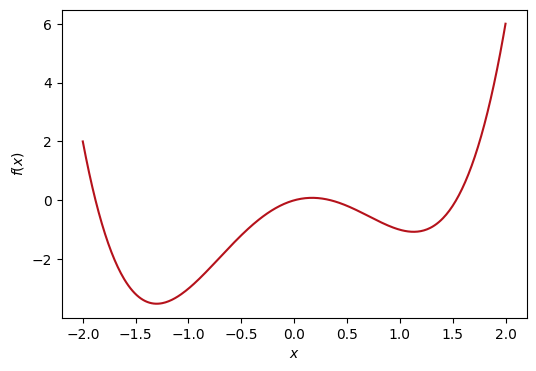

x0 = -0.5: gradient descent -> -1.3008 (f = -3.514); Newton on f' -> -1.3008 (f'' = +14.3); minimize -> -1.3008
x0 = +0.5: gradient descent -> +1.1309 (f = -1.070); Newton on f' -> +0.1699 (f'' = -5.7); minimize -> +1.1309


In [12]:
from scipy.optimize import minimize

f_opt = lambda x: x**4 - 3 * x**2 + x
fp_opt = lambda x: 4 * x**3 - 6 * x + 1
fpp_opt = lambda x: 12 * x**2 - 6

xx = np.linspace(-2, 2, 400)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(xx, f_opt(xx), color="#B5121B")
ax.set_xlabel("$x$")
ax.set_ylabel("$f(x)$")
plt.show()

for x0 in [-0.5, 0.5]:
    x = x0
    for _ in range(2000):
        x -= 0.01 * fp_opt(x)
    xn, _ = newton(fp_opt, fpp_opt, x0)
    res = minimize(lambda v: f_opt(v[0]), [x0])
    print(f"x0 = {x0:+.1f}: gradient descent -> {x:+.4f} (f = {f_opt(x):.3f}); "
          f"Newton on f' -> {xn:+.4f} (f'' = {fpp_opt(xn):+.1f}); minimize -> {res.x[0]:+.4f}")

<span style="color:#38614A">**Answer.**</span> Gradient descent and `minimize` find the global minimum $x \approx -1.30$ ($f = -3.51$) from $x_0 = -0.5$, but the local minimum $x \approx 1.13$ ($f = -1.07$) from $x_0 = +0.5$: every local method finds *a* minimum, not *the* minimum. Newton on $f'$ from $+0.5$ converges to $x \approx 0.17$, where $f'' < 0$: a **maximum**. Newton finds stationary points, not minima, so always check the second derivative (or the function value).

## <span style="color:#FD9029">Extension B (optional): Newton in two dimensions</span>

The lecture's example: find where the circle $x^2 + y^2 = 4$ meets the curve $y = e^x$. Write $\mathbf{F}(x, y) = (x^2 + y^2 - 4,\; e^x - y) = \mathbf{0}$ with Jacobian

$$J = \begin{pmatrix} 2x & 2y \\ e^x & -1 \end{pmatrix}.$$

Each Newton step solves $J\,\Delta\mathbf{x} = -\mathbf{F}$ (use `np.linalg.solve`; never invert $J$). Find both intersections by trying different starting points, including $(0, 0)$. Check with `scipy.optimize.root`.

In [13]:
from scipy.optimize import root

F = lambda v: np.array([v[0]**2 + v[1]**2 - 4, np.exp(v[0]) - v[1]])
J = lambda v: np.array([[2 * v[0], 2 * v[1]], [np.exp(v[0]), -1.0]])

def newton_2d(F, J, v0, tol=1e-12, max_iter=50):
    v = np.array(v0, dtype=float)
    for n in range(max_iter):
        step = np.linalg.solve(J(v), -F(v))
        v = v + step
        if np.linalg.norm(step) < tol:
            return v, n + 1
    return v, max_iter

for start in [(1, 1), (-2, 0), (-1, 1), (0, 0)]:
    try:
        v, n = newton_2d(F, J, start)
        print(f"start {start}: ({v[0]:.6f}, {v[1]:.6f}) in {n} steps, |F| = {np.linalg.norm(F(v)):.0e}")
    except np.linalg.LinAlgError as err:
        print(f"start {start}: failed ({err})")
print("scipy root:", root(F, [1, 1]).x, root(F, [-2, 0]).x)

start (1, 1): (0.639263, 1.895084) in 6 steps, |F| = 0e+00
start (-2, 0): (-1.995373, 0.135963) in 5 steps, |F| = 0e+00
start (-1, 1): (-1.995373, 0.135963) in 7 steps, |F| = 0e+00
start (0, 0): failed (Singular matrix)
scipy root: [0.63926307 1.89508383] [-1.99537317  0.13596291]


<span style="color:#38614A">**Answer.**</span> The intersections are $(0.6393, 1.8951)$ and $(-1.9954, 0.1360)$; which one Newton finds depends on the start. From $(0, 0)$ the Jacobian is singular ($\det J = 0$), so the very first step fails. In several dimensions there is no bracket, so the starting guess matters even more than in 1-D.

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>